# credit-pricer: demo

A tour of the library on **synthetic data** (every input file in `data/` is generated by
`scripts/make_synthetic_data.py` and is illustrative only, not market data):

1. discount and survival curves,
2. single-name CDS pricing and risk,
3. validation against QuantLib,
4. CDS index intrinsic spread and basis,
5. synthetic CDO tranches and base correlation,
6. credit-linked notes.

Each section reproduces the matching figure from `scripts/make_figures.py` (light theme).

In [1]:
import sys
from io import BytesIO
from pathlib import Path

from IPython.display import Image, display

sys.path.insert(0, str(Path.cwd().parent / "scripts"))
import make_figures as mf  # figure functions shared with the README images

from credit_pricer.cds import CDS, cs01, price_cds, recovery_sensitivity
from credit_pricer.cln import CreditLinkedNote, value_cln
from credit_pricer.data import VALUATION_DATE
from credit_pricer.index import index_intrinsic
from credit_pricer.tranches import calibrate_base_correlation

ctx = mf.Context()  # caches curves, index constituents and the tranche pricer


def show(fig):
    buf = BytesIO()
    fig.savefig(buf, format="png", dpi=110, bbox_inches="tight", pad_inches=0.15)
    mf.plt.close(fig)
    display(Image(buf.getvalue()))


print("valuation date:", VALUATION_DATE)

valuation date: 2026-11-05


## 1. Curves

The discount curve is bootstrapped from synthetic deposits and OIS-style swaps (log-linear
discount factors). Survival curves are bootstrapped from CDS par spreads with
piecewise-constant hazard rates (ISDA conventions, recovery 40%).

In [2]:
discount = ctx.discount
for t in (1, 2, 5, 10, 30):
    print(f"{t:>2}y  DF = {float(discount.df(t)):.6f}  zero = {float(discount.zero_rate(t)):.4%}")

 1y  DF = 0.961212  zero = 3.9560%
 2y  DF = 0.927604  zero = 3.7575%
 5y  DF = 0.835357  zero = 3.5979%
10y  DF = 0.687735  zero = 3.7435%
30y  DF = 0.319292  zero = 3.8055%


ALPHA_IG_LOW   hazards: 0.3026%, 0.5948%, 0.9876%, 1.6269%, 1.9344%, 2.0472%
BRAVO_IG_MID   hazards: 0.9246%, 1.6219%, 2.4140%, 3.3558%, 3.6510%, 3.5963%
CHARLIE_HY     hazards: 4.0346%, 5.9100%, 7.5074%, 8.7327%, 8.5461%, 8.1252%


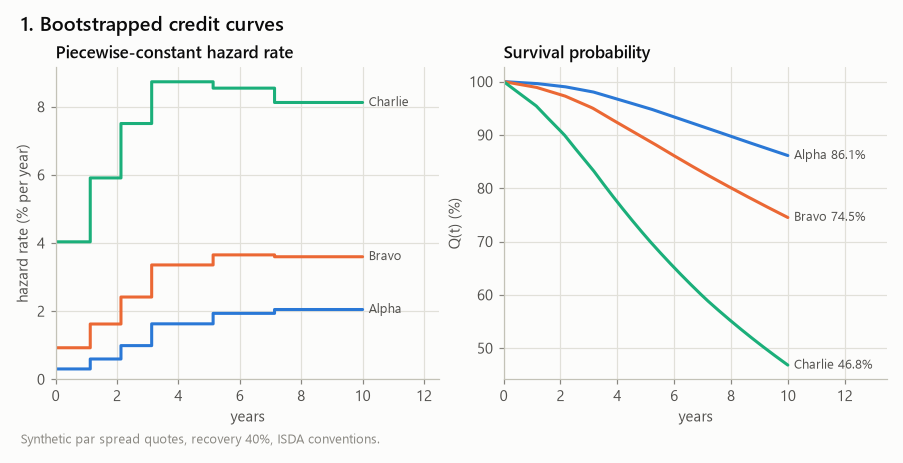

In [3]:
for name, (_, _, curve) in ctx.names.items():
    h = ", ".join(f"{x:.4%}" for x in curve.hazards)
    print(f"{name:<14} hazards: {h}")
show(mf.fig_hazard_survival(ctx, mf.LIGHT))

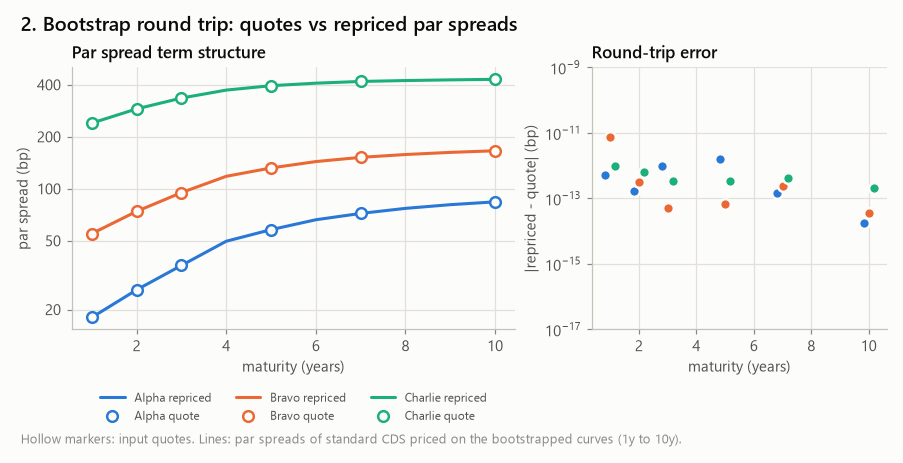

In [4]:
show(mf.fig_round_trip(ctx, mf.LIGHT))

## 2. Single-name CDS

A 5y CDS on the mid-grade name with the standard 100 bp coupon: legs, par spread,
upfront, RPV01, CS01 and recovery sensitivity.

In [5]:
tenors, spreads, curve = ctx.names["BRAVO_IG_MID"]
cds = CDS.standard(VALUATION_DATE, 5, 0.01)
v = price_cds(cds, discount, curve)
print(f"maturity          {cds.maturity}")
print(f"protection leg    {v.protection_leg:.6f}")
print(f"RPV01 (clean)     {v.rpv01:.6f} years")
print(f"par spread        {v.par_spread * 1e4:.4f} bp")
print(f"upfront (clean)   {v.upfront:.6%} of notional, paid at cash settlement")
print(f"accrued           {v.accrued:.6%}")
print(f"CS01 (parallel)   {cs01(cds, discount, tenors, spreads) * 1e4:.4f} per 10k notional")
rs = recovery_sensitivity(cds, discount, tenors, spreads)
print(f"recovery +1%      rebuilt curve {rs.rebuilt * 1e4:+.4f},"
      f" fixed hazard {rs.fixed_hazard * 1e4:+.4f} per 10k")

maturity          2031-12-20
protection leg    0.059630
RPV01 (clean)     4.517391 years
par spread        132.0000 bp
upfront (clean)   1.446427% of notional, paid at cash settlement
accrued           0.127778%
CS01 (parallel)   4.4559 per 10k notional
recovery +1%      rebuilt curve -0.1043, fixed hazard -9.9383 per 10k


isda          par spread 132.000000 bp
isda_halfday  par spread 131.995967 bp
midpoint      par spread 132.010251 bp


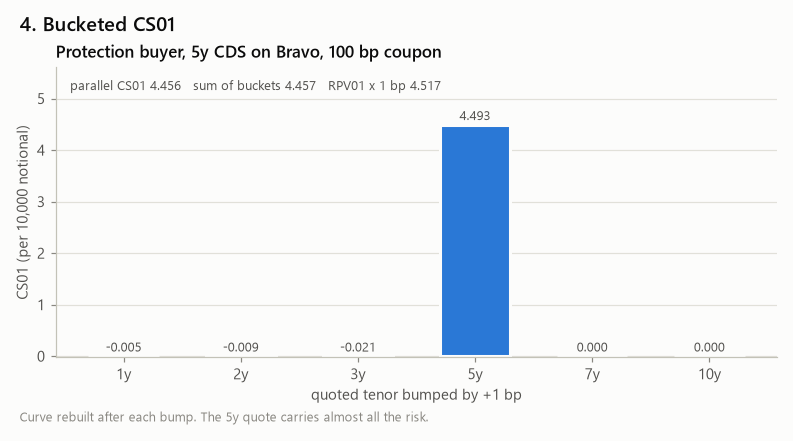

In [6]:
for method in ("isda", "isda_halfday", "midpoint"):
    s = price_cds(cds, discount, curve, method).par_spread
    print(f"{method:<13} par spread {s * 1e4:.6f} bp")
show(mf.fig_cs01(ctx, mf.LIGHT))

## 3. Validation against QuantLib

The same curves are rebuilt node for node in QuantLib and priced with `IsdaCdsEngine`
and `MidPointCdsEngine`; QuantLib also bootstraps its own hazard curve from the same
quotes. Full tables: `docs/validation.md`.

isda          max |d par spread| 5.0e-04 bp, max |d upfront| 5.0e-05 bp
isda_halfday  max |d par spread| 1.4e-04 bp, max |d upfront| 4.6e-05 bp
midpoint      max |d par spread| 2.0e-11 bp, max |d upfront| 8.2e-12 bp
bootstrap     max |d Q(T)| 1.0e-07


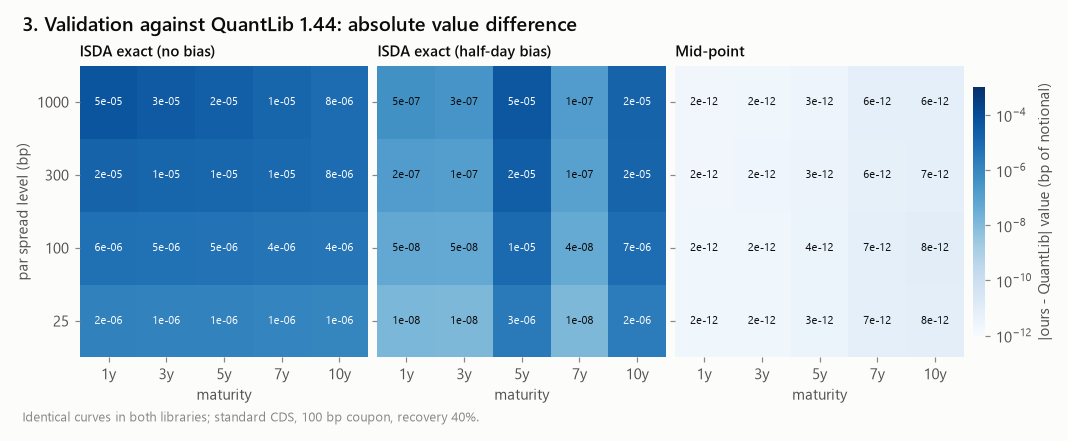

In [7]:
from credit_pricer.validation import run_validation

engine_rows, boot_rows = run_validation(discount)
for m in ("isda", "isda_halfday", "midpoint"):
    rs_ = [r for r in engine_rows if r.method == m]
    print(f"{m:<13} max |d par spread| {max(abs(r.d_par_spread_bp) for r in rs_):.1e} bp,"
          f" max |d upfront| {max(abs(r.d_upfront_bp) for r in rs_):.1e} bp")
print(f"bootstrap     max |d Q(T)| {max(abs(r.d_survival) for r in boot_rows):.1e}")
show(mf.fig_validation(ctx, mf.LIGHT))

## 4. CDS index

125 synthetic constituents. The intrinsic spread is the RPV01-weighted average of the
constituent par spreads; the quoted index spread differs from it by the index basis,
which a hazard-rate multiplier per maturity segment removes.

The adjustment matches the *value* (upfront) implied by each quote under the flat-curve
convention, so the adjusted intrinsic *spread* is close to, but not exactly, the quoted
spread.

 3y quoted   45.51  intrinsic   47.01  basis -1.50  adjusted intrinsic   45.62 bp
 5y quoted   73.06  intrinsic   75.56  basis -2.50  adjusted intrinsic   73.27 bp
 7y quoted   88.68  intrinsic   91.68  basis -3.00  adjusted intrinsic   88.81 bp


10y quoted   99.17  intrinsic  102.67  basis -3.50  adjusted intrinsic   99.18 bp
hazard multipliers: [0.9701, 0.9683, 0.9652, 0.9572]


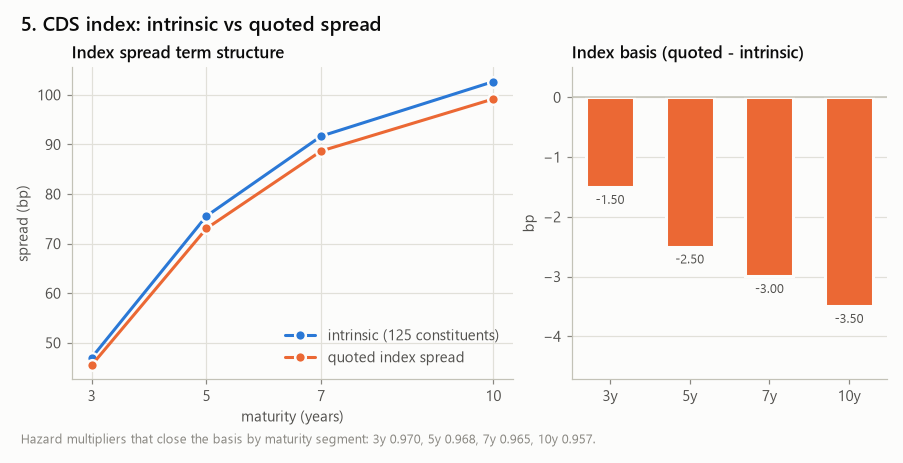

In [8]:
d = ctx.index
for k, q in zip(d.quoted_tenors, d.quoted_spreads):
    intr = index_intrinsic(VALUATION_DATE, k, d.coupon, ctx.members, discount).spread
    adj = index_intrinsic(VALUATION_DATE, k, d.coupon, ctx.adjusted.constituents, discount).spread
    print(f"{k:>2}y quoted {q * 1e4:7.2f}  intrinsic {intr * 1e4:7.2f}"
          f"  basis {(q - intr) * 1e4:+.2f}  adjusted intrinsic {adj * 1e4:7.2f} bp")
print("hazard multipliers:", [round(f, 4) for f in ctx.adjusted.factors])
show(mf.fig_index(ctx, mf.LIGHT))

## 5. Synthetic CDO tranches

One-factor Gaussian copula. Large-homogeneous-pool (LHP) closed form vs the exact
finite-pool recursion, tranche expected loss vs correlation, and base correlation
calibrated from synthetic upfront + running quotes.

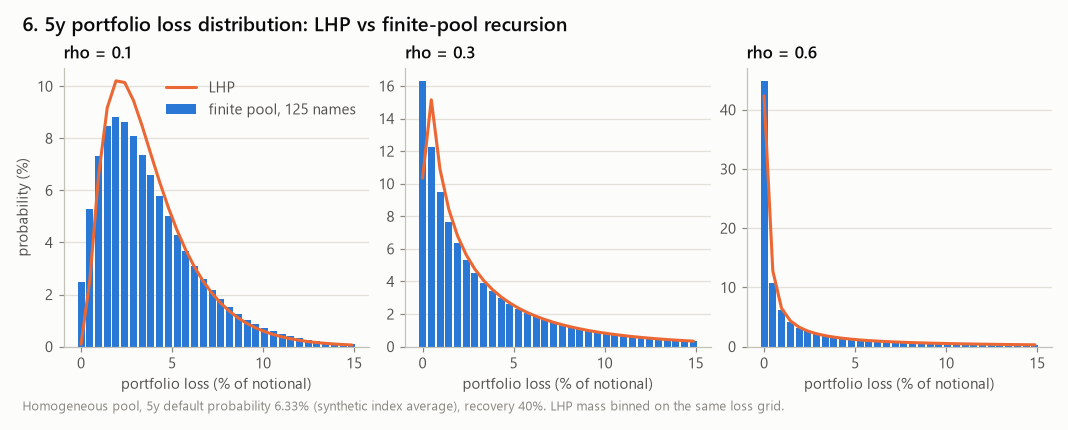

In [9]:
show(mf.fig_loss_distribution(ctx, mf.LIGHT))

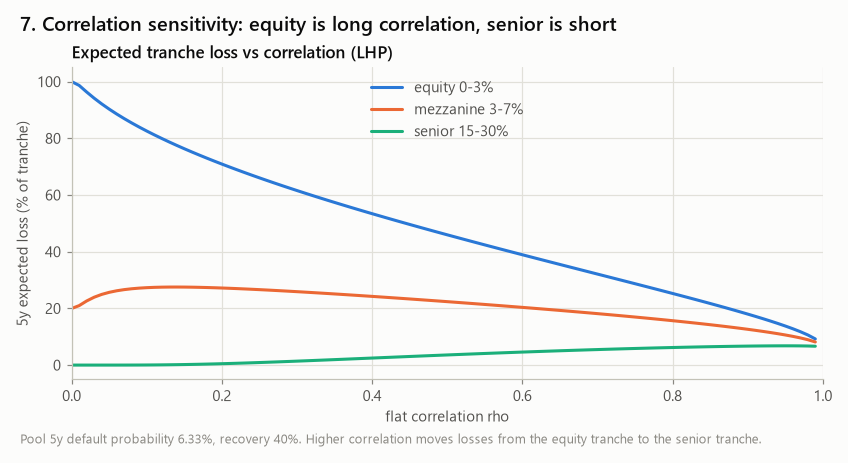

In [10]:
show(mf.fig_tranche_el(ctx, mf.LIGHT))

tranche     upfront   coupon   base corr  (generating)
  0%-3%   38.8039%    500bp   0.300000   (0.30)
  3%-7%   -5.6264%    500bp   0.410000   (0.41)
  7%-10%   2.1702%    100bp   0.480000   (0.48)
 10%-15%  -0.6961%    100bp   0.570000   (0.57)
 15%-30%  -2.5916%    100bp   0.740000   (0.74)
flat rho=0.3 [0%, 3%] fair spread   1636.4 bp
flat rho=0.3 [3%, 7%] fair spread    541.1 bp
flat rho=0.3 [7%, 10%] fair spread    243.2 bp


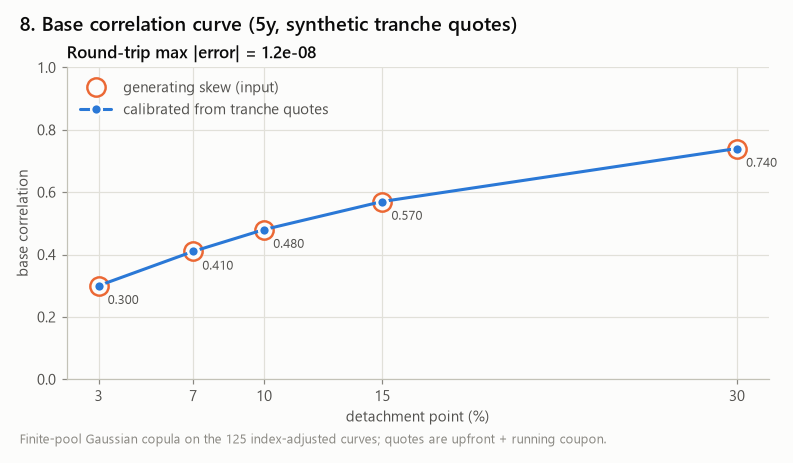

In [11]:
tr = ctx.tranches
curve_bc = calibrate_base_correlation(ctx.pricer, tr.quotes)
print("tranche     upfront   coupon   base corr  (generating)")
for q, pt, g in zip(tr.quotes, curve_bc, tr.generating_correlations):
    print(f"{q.attach:>4.0%}-{q.detach:<4.0%} {q.upfront:8.4%} {q.coupon * 1e4:6.0f}bp"
          f"   {pt.correlation:.6f}   ({g:.2f})")
for a, b in [(0.0, 0.03), (0.03, 0.07), (0.07, 0.10)]:
    legs = ctx.pricer.legs(a, b, 0.3)
    print(f"flat rho=0.3 [{a:.0%}, {b:.0%}] fair spread {legs.fair_spread * 1e4:8.1f} bp")
show(mf.fig_base_correlation(ctx, mf.LIGHT))

## 6. Credit-linked note

A funded note: floating coupon plus a spread, par at maturity, recovery on a reference
default, discounted with the issuer's funding spread.

funding     0 bp: CLN fair spread  133.22 bp vs CDS par + funding  132.00 bp
funding    50 bp: CLN fair spread  182.83 bp vs CDS par + funding  181.32 bp
funding   150 bp: CLN fair spread  282.24 bp vs CDS par + funding  279.95 bp


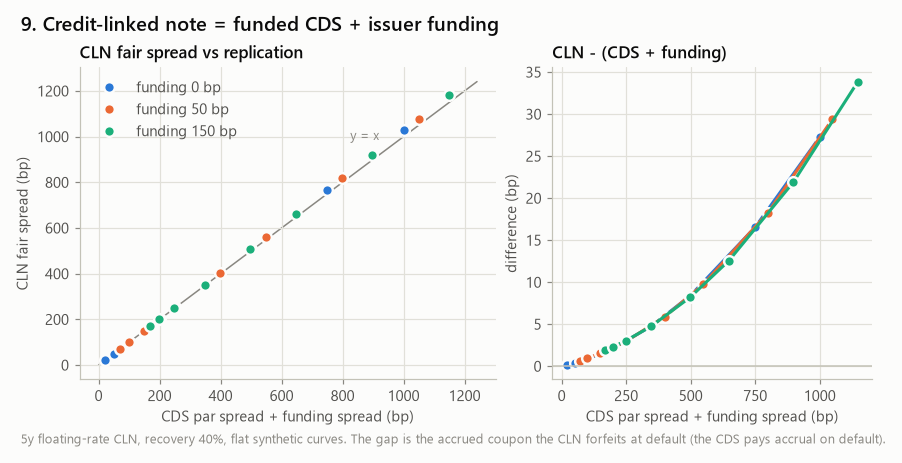

In [12]:
note = CreditLinkedNote.standard(VALUATION_DATE, 5, 0.0)
cds_par = price_cds(cds, discount, curve).par_spread
for f in (0.0, 0.005, 0.015):
    fair = value_cln(note, discount, curve, f).fair_spread
    print(f"funding {f * 1e4:5.0f} bp: CLN fair spread {fair * 1e4:7.2f} bp"
          f" vs CDS par + funding {(cds_par + f * 360 / 365) * 1e4:7.2f} bp")
show(mf.fig_cln(ctx, mf.LIGHT))